In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [4]:
df = pd.read_csv("8.supermarket.csv")
df

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.300,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.920,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.500,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.200,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.930,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052
...,...,...,...,...,...,...,...,...,...,...,...,...
8518,FDF22,6.865,Low Fat,0.056783,Snack Foods,214.5218,OUT013,1987,High,Tier 3,Supermarket Type1,2778.3834
8519,FDS36,8.380,Regular,0.046982,Baking Goods,108.1570,OUT045,2002,NaN,Tier 2,Supermarket Type1,549.2850
8520,NCJ29,10.600,Low Fat,0.035186,Health and Hygiene,85.1224,OUT035,2004,Small,Tier 2,Supermarket Type1,1193.1136
8521,FDN46,7.210,Regular,0.145221,Snack Foods,103.1332,OUT018,2009,Medium,Tier 3,Supermarket Type2,1845.5976


In [5]:
os.makedirs("Week3_Output", exist_ok=True)
sns.set_theme(style="whitegrid")

In [6]:
df.head()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


In [7]:
df.tail()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
8518,FDF22,6.865,Low Fat,0.056783,Snack Foods,214.5218,OUT013,1987,High,Tier 3,Supermarket Type1,2778.3834
8519,FDS36,8.380,Regular,0.046982,Baking Goods,108.1570,OUT045,2002,NaN,Tier 2,Supermarket Type1,549.2850
8520,NCJ29,10.600,Low Fat,0.035186,Health and Hygiene,85.1224,OUT035,2004,Small,Tier 2,Supermarket Type1,1193.1136
8521,FDN46,7.210,Regular,0.145221,Snack Foods,103.1332,OUT018,2009,Medium,Tier 3,Supermarket Type2,1845.5976
8522,DRG01,14.800,Low Fat,0.044878,Soft Drinks,75.4670,OUT046,1997,Small,Tier 1,Supermarket Type1,765.6700


In [9]:
df.columns

Index(['Item_Identifier', 'Item_Weight', 'Item_Fat_Content', 'Item_Visibility',
       'Item_Type', 'Item_MRP', 'Outlet_Identifier',
       'Outlet_Establishment_Year', 'Outlet_Size', 'Outlet_Location_Type',
       'Outlet_Type', 'Item_Outlet_Sales'],
      dtype='object')

In [11]:
df.shape

(8523, 12)

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   object 
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   object 
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   object 
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   object 
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   object 
 9   Outlet_Location_Type       8523 non-null   object 
 10  Outlet_Type                8523 non-null   object 
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


In [13]:
df.isnull().sum()

Item_Identifier                 0
Item_Weight                  1463
Item_Fat_Content                0
Item_Visibility                 0
Item_Type                       0
Item_MRP                        0
Outlet_Identifier               0
Outlet_Establishment_Year       0
Outlet_Size                  2410
Outlet_Location_Type            0
Outlet_Type                     0
Item_Outlet_Sales               0
dtype: int64

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
# Remove duplicate records
df = df.drop_duplicates().copy()

In [16]:
# Convert numerical columns
numeric_columns = [
    "Item_Weight",
    "Item_Visibility",
    "Item_MRP",
    "Outlet_Establishment_Year",
    "Item_Outlet_Sales"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [17]:
# Fill missing numerical values with median
for col in numeric_columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())

In [18]:
# Fill missing categorical values with mode
categorical_columns = [
    "Item_Fat_Content",
    "Item_Type",
    "Outlet_Size",
    "Outlet_Location_Type",
    "Outlet_Type"
]

for col in categorical_columns:
    if df[col].isnull().any():
        mode = df[col].mode()
        if not mode.empty:
            df[col] = df[col].fillna(mode.iloc[0])

In [19]:
# Standardize inconsistent fat-content labels
df["Item_Fat_Content"] = df["Item_Fat_Content"].replace({
    "low fat": "Low Fat",
    "LF": "Low Fat",
    "reg": "Regular"
})

In [20]:
# Save cleaned dataset
df.to_csv(
    "Week3_Output/cleaned_supermarket.csv",
    index=False
)

In [21]:
df.isnull().sum()

Item_Identifier              0
Item_Weight                  0
Item_Fat_Content             0
Item_Visibility              0
Item_Type                    0
Item_MRP                     0
Outlet_Identifier            0
Outlet_Establishment_Year    0
Outlet_Size                  0
Outlet_Location_Type         0
Outlet_Type                  0
Item_Outlet_Sales            0
dtype: int64

### exploratory data Analysis

In [22]:
df.describe()

,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year,Item_Outlet_Sales
count,8523.00000,8523.000000,8523.000000,8523.000000,8523.000000
mean,12.81342,0.066132,140.992782,1997.831867,2181.288914
std,4.22724,0.051598,62.275067,8.371760,1706.499616
min,4.55500,0.000000,31.290000,1985.000000,33.290000
25%,9.31000,0.026989,93.826500,1987.000000,834.247400
50%,12.60000,0.053931,143.012800,1999.000000,1794.331000
75%,16.00000,0.094585,185.643700,2004.000000,3101.296400
max,21.35000,0.328391,266.888400,2009.000000,13086.964800


In [23]:
total_sales = df["Item_Outlet_Sales"].sum()
average_sales = df["Item_Outlet_Sales"].mean()
total_items = len(df)
average_mrp = df["Item_MRP"].mean()

print("\nKEY PERFORMANCE INDICATORS")
print("Total Sales:", round(total_sales, 2))
print("Average Sales per Record:", round(average_sales, 2))
print("Total Records:", total_items)
print("Average Item MRP:", round(average_mrp, 2))


KEY PERFORMANCE INDICATORS
Total Sales: 18591125.41
Average Sales per Record: 2181.29
Total Records: 8523
Average Item MRP: 140.99


### BAR Chart

In [24]:
# Total sales by item type
item_sales = (
    df.groupby("Item_Type")["Item_Outlet_Sales"]
    .sum()
    .sort_values(ascending=False)
)

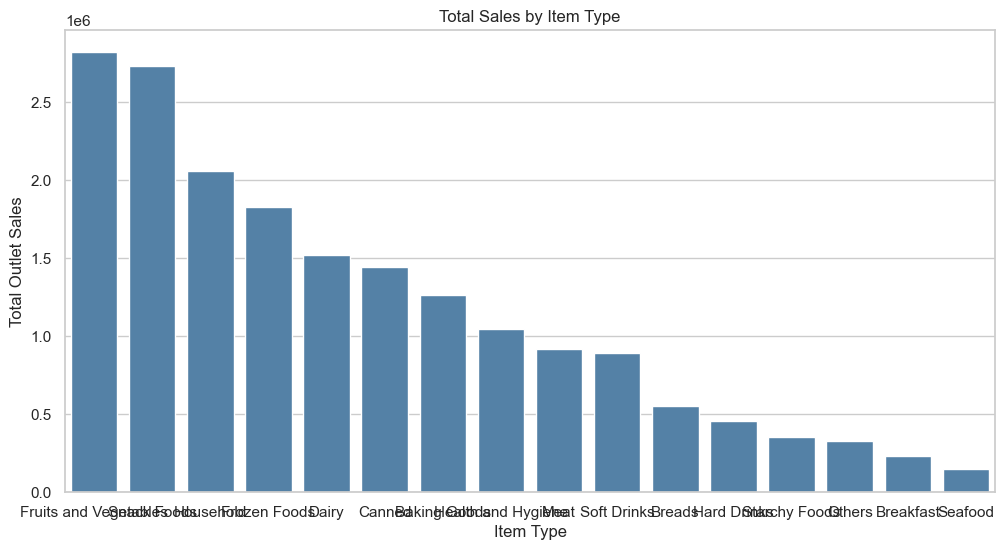

In [25]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=item_sales.index,
    y=item_sales.values,
    color="steelblue")

plt.title("Total Sales by Item Type")
plt.xlabel("Item Type")
plt.ylabel("Total Outlet Sales")

plt.show()

### LINE Chart

In [26]:
# Average Sales by Outlet Establishment Year

year_sales = (
    df.groupby("Outlet_Establishment_Year")["Item_Outlet_Sales"]
    .mean()
    .sort_index()
)

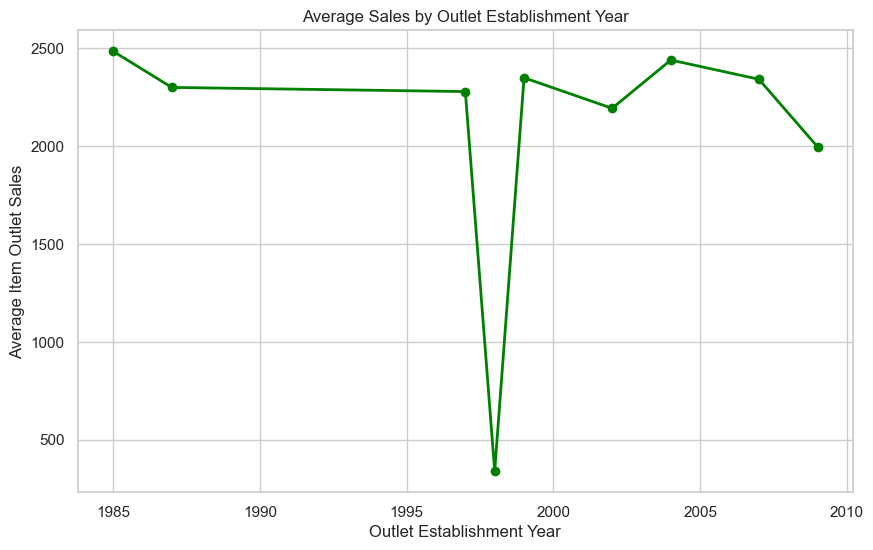

In [28]:
plt.figure(figsize=(10, 6))

plt.plot(
    year_sales.index,
    year_sales.values,
    marker="o",
    linewidth=2,
    color="green")

plt.title("Average Sales by Outlet Establishment Year")
plt.xlabel("Outlet Establishment Year")
plt.ylabel("Average Item Outlet Sales")

plt.show()

### SCATTER PLOT

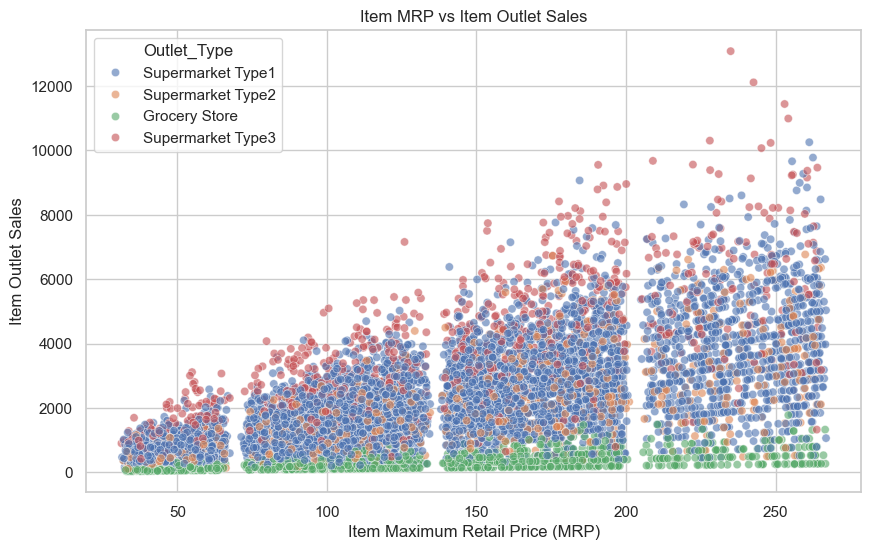

In [30]:
# Item MRP vs Outlet Sales

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Item_MRP",
    y="Item_Outlet_Sales",
    hue="Outlet_Type",
    alpha=0.6)

plt.title("Item MRP vs Item Outlet Sales")
plt.xlabel("Item Maximum Retail Price (MRP)")
plt.ylabel("Item Outlet Sales")

plt.show()

### HEATMAP

In [31]:
# Correlation Between Numerical Variables

numeric_df = df.select_dtypes(include=np.number)
correlation = numeric_df.corr()

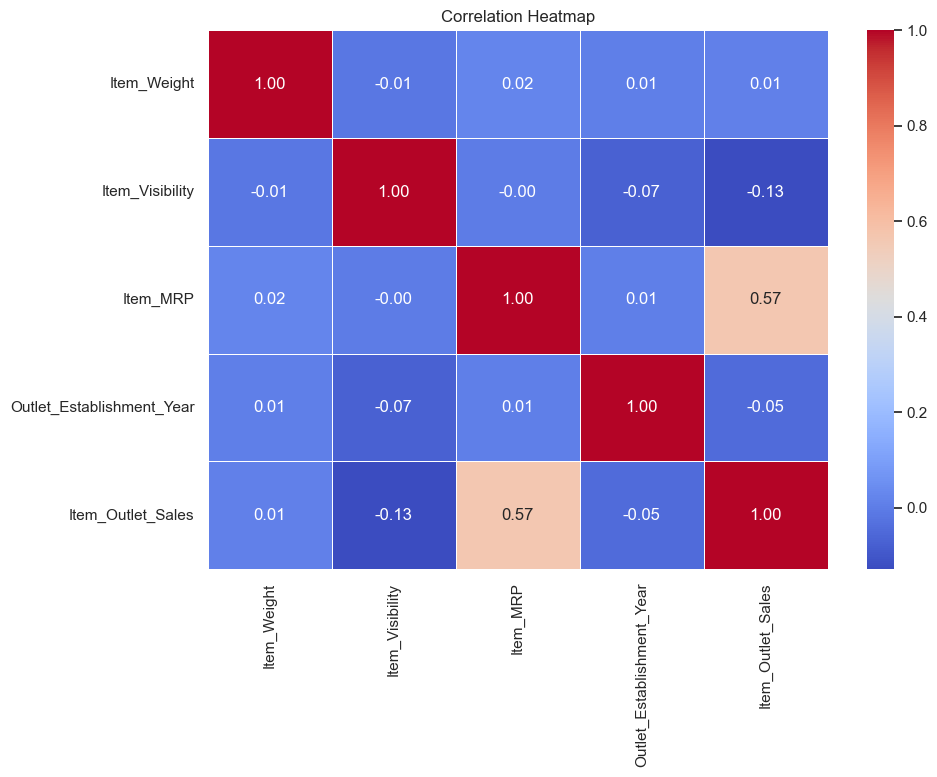

In [32]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

### Findings

In [33]:
highest_item_type = item_sales.idxmax()
lowest_item_type = item_sales.idxmin()

print("Highest Sales Item Type:", highest_item_type)
print("Lowest Sales Item Type:", lowest_item_type)

Highest Sales Item Type: Fruits and Vegetables
Lowest Sales Item Type: Seafood


In [34]:
highest_year = year_sales.idxmax()
highest_year_sales = year_sales.max()

print("Year with Highest Average Sales:", highest_year)
print("Highest Average Sales:", round(highest_year_sales, 2))

Year with Highest Average Sales: 1985
Highest Average Sales: 2483.68


In [36]:
mrp_correlation = df[
    ["Item_MRP", "Item_Outlet_Sales"]
].corr().iloc[0, 1]

print("\nPROJECT FINDINGS")

print("MRP and Sales Correlation:", round(mrp_correlation, 3))


PROJECT FINDINGS
MRP and Sales Correlation: 0.568


In [37]:
print("\nSales by Item Type:")
print(item_sales.round(2))


Sales by Item Type:
Item_Type
Fruits and Vegetables    2820059.82
Snack Foods              2732786.09
Household                2055493.71
Frozen Foods             1825734.79
Dairy                    1522594.05
Canned                   1444151.49
Baking Goods             1265525.34
Health and Hygiene       1045200.14
Meat                      917565.61
Soft Drinks               892897.72
Breads                    553237.19
Hard Drinks               457793.43
Starchy Foods             351401.25
Others                    325517.61
Breakfast                 232298.95
Seafood                   148868.22
Name: Item_Outlet_Sales, dtype: float64
